In [72]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, recall_score, precision_score, classification_report

In [73]:
#load datasets
data= load_breast_cancer()

X=pd.DataFrame(data.data, columns=data.feature_names)
y=pd.Series(data.target, name='target')
X.head(2)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902


In [74]:
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

Feature matrix shape: (569, 30)
Target shape: (569,)


In [75]:
y.value_counts()

,count
target,
1,357
0,212


In [76]:
#Train Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)
print("Training samples:", X_train.shape[0])
print("Test samples:", X_test.shape[0])

Training samples: 426
Test samples: 143


In [77]:
#besline
rf_baseline= RandomForestClassifier( n_estimators=100, random_state=42 )
rf_baseline.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [78]:
#predict
y_pred=rf_baseline.predict(X_test)
#Model Evaluation
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.958041958041958


In [79]:
#Classification Report
print(classification_report(y_test, y_pred, target_names=data.target_names))

              precision    recall  f1-score   support

   malignant       0.96      0.92      0.94        53
      benign       0.96      0.98      0.97        90

    accuracy                           0.96       143
   macro avg       0.96      0.95      0.95       143
weighted avg       0.96      0.96      0.96       143



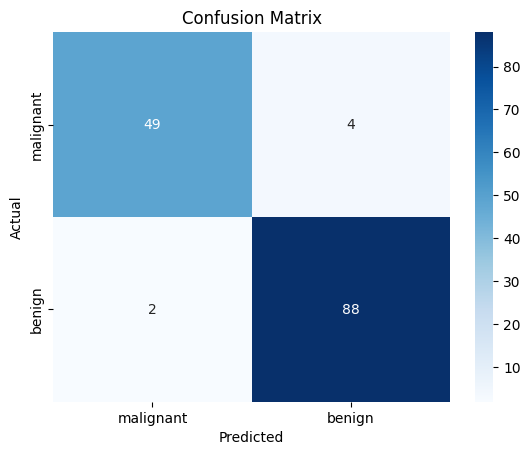

In [80]:
#confusion matrix
cm=confusion_matrix(y_test, y_pred)
sns.heatmap(
    cm, annot=True, cmap='Blues',
    xticklabels=data.target_names,
    yticklabels= data.target_names
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

#2- Feature Importance

In [81]:
#feature importance
importance= pd.Series(
    rf_baseline.feature_importances_,
    index=X.columns
).sort_values(ascending=False)
importance.head(10)

,0
worst area,0.149674
worst concave points,0.127189
mean concave points,0.104650
worst radius,0.086963
worst perimeter,0.080299
mean perimeter,0.080037
mean concavity,0.055420
mean radius,0.053665
mean area,0.044062
area error,0.024557


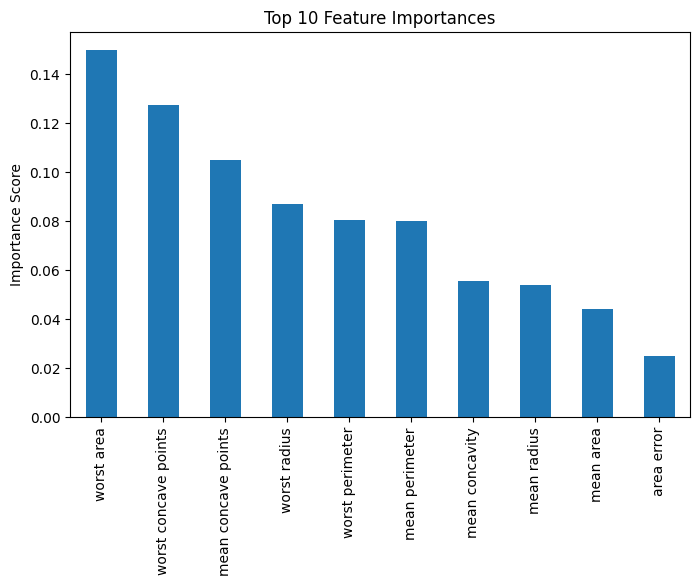

In [82]:
#visualization
plt.figure(figsize=(8,5))
importance.head(10).plot(kind='bar')
plt.title("Top 10 Feature Importances")
plt.ylabel("Importance Score")
plt.show()

# 3-  Hyperparameter Tuning

In [83]:
#key hyperparameters
param_grid= {
    'n_estimators':[100,150,175,200],
    'max_depth':[None,5,10,15],
    "max_features":['sqrt','log2']
}

In [84]:
#GridSearchCV for Tuning
grid_rf= GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)
grid_rf.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=RandomForestClassifier(random_state=42), n_jobs=-1,
             param_grid={'max_depth': [None, 5, 10, 15],
                         'max_features': ['sqrt', 'log2'],
                         'n_estimators': [100, 150, 175, 200]},
             scoring='f1')

In [85]:
#showing output
print('best parameter:',grid_rf.best_params_)

best parameter: {'max_depth': None, 'max_features': 'log2', 'n_estimators': 100}


In [86]:
#evaluting Tuned Model
best_rf= grid_rf.best_estimator_
y_pred_best= best_rf.predict(X_test)
print('Classification Report:\n', classification_report(y_test, y_pred_best, target_names=data.target_names ))

Classification Report:
               precision    recall  f1-score   support

   malignant       0.96      0.92      0.94        53
      benign       0.96      0.98      0.97        90

    accuracy                           0.96       143
   macro avg       0.96      0.95      0.95       143
weighted avg       0.96      0.96      0.96       143

